### Mount Drive, initialise Spark, and locate the saved Task 2 train/test outputs.


In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=False)

from pathlib import Path
import json, time, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F
from pyspark.ml.classification import (
    LogisticRegression, RandomForestClassifier,
    GBTClassifier, MultilayerPerceptronClassifier
)
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

spark = (
    SparkSession.builder
    .appName("7006SCN_Task3_WESAD_Classification")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")

TASK2_DIR = Path("/content/drive/MyDrive/wesad_task2_outputs")
TRAIN_PATH = TASK2_DIR / "train_processed"
TEST_PATH = TASK2_DIR / "test_processed"
TASK2_MANIFEST = TASK2_DIR / "task2_manifest.json"

if not TRAIN_PATH.exists() or not TEST_PATH.exists():
    raise FileNotFoundError(
        "Task 2 processed outputs were not found. Finish the Task 2 notebook successfully first."
    )
if not TASK2_MANIFEST.exists():
    raise FileNotFoundError("Task 2 manifest is missing; verify Task 2 completed successfully.")

task2_manifest = json.loads(TASK2_MANIFEST.read_text(encoding="utf-8"))
if task2_manifest.get("status") != "verified":
    raise RuntimeError("Task 2 manifest is not marked verified.")

print("Spark version:", spark.version)
print("Task 2 manifest status:", task2_manifest["status"])
print("Train path:", TRAIN_PATH)
print("Test path:", TEST_PATH)

Mounted at /content/drive
Spark version: 4.0.4
Task 2 manifest status: verified
Train path: /content/drive/MyDrive/wesad_task2_outputs/train_processed
Test path: /content/drive/MyDrive/wesad_task2_outputs/test_processed


### Load processed data and verify feature vectors, labels, and participant-separated split.


In [ ]:
train = spark.read.parquet(str(TRAIN_PATH)).cache()
test = spark.read.parquet(str(TEST_PATH)).cache()

required = {"features", "label", "target_text", "subject_id", "sample_index"}
for name, frame in [("train", train), ("test", test)]:
    missing = sorted(required - set(frame.columns))
    if missing:
        raise ValueError(f"{name} data is missing required columns: {missing}")

train_rows = train.count()
test_rows = test.count()
train_subjects = sorted(r["subject_id"] for r in train.select("subject_id").distinct().collect())
test_subjects = sorted(r["subject_id"] for r in test.select("subject_id").distinct().collect())
overlap = sorted(set(train_subjects).intersection(test_subjects))

if train_rows == 0 or test_rows == 0:
    raise RuntimeError("Training or test dataset is empty.")
if overlap:
    raise RuntimeError(f"Participant leakage detected: {overlap}")
if train.select("label").distinct().count() != 2:
    raise RuntimeError("Training data must contain both binary classes.")
if test.select("label").distinct().count() != 2:
    raise RuntimeError("Test data must contain both binary classes.")

print(f"Training rows: {train_rows:,}")
print(f"Test rows: {test_rows:,}")
print("Training participants:", train_subjects)
print("Test participants:", test_subjects)
print("Train/test participant overlap:", overlap)
print("Training class distribution:")
train.groupBy("label", "target_text").count().orderBy("label").show()
print("Test class distribution:")
test.groupBy("label", "target_text").count().orderBy("label").show()

Training rows: 25,137,704
Test rows: 6,332,899
Training participants: ['S10', 'S11', 'S13', 'S14', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9']
Test participants: ['S15', 'S16', 'S17']
Train/test participant overlap: []
Training class distribution:
+-----+-----------+--------+
|label|target_text|   count|
+-----+-----------+--------+
|  0.0| non_stress|19618904|
|  1.0|     stress| 5518800|
+-----+-----------+--------+

Test class distribution:
+-----+-----------+-------+
|label|target_text|  count|
+-----+-----------+-------+
|  0.0| non_stress|4875498|
|  1.0|     stress|1457401|
+-----+-----------+-------+



### Create a reproducible modelling sample to keep cross-validation feasible in Colab.


In [ ]:
# Stratified sampling is deterministic. Increase these fractions only if runtime permits.
MAX_TRAIN_ROWS = 200_000
MAX_TEST_ROWS = 100_000
seed = 42

train_total = train.count()
test_total = test.count()

def bounded_stratified_sample(frame, total_rows, max_rows, seed):
    if total_rows <= max_rows:
        return frame
    fraction = min(1.0, (max_rows * 1.15) / total_rows)
    labels = [r["label"] for r in frame.select("label").distinct().collect()]
    fractions = {label: fraction for label in labels}
    sampled = frame.stat.sampleBy("label", fractions=fractions, seed=seed)
    if sampled.count() > max_rows:
        sampled = sampled.orderBy(F.rand(seed=seed)).limit(max_rows)
    return sampled

train_model = bounded_stratified_sample(train, train_total, MAX_TRAIN_ROWS, seed).cache()
test_model = bounded_stratified_sample(test, test_total, MAX_TEST_ROWS, seed + 1).cache()

actual_train = train_model.count()
actual_test = test_model.count()
if train_model.select("label").distinct().count() != 2 or test_model.select("label").distinct().count() != 2:
    raise RuntimeError("Sample lost a class; increase sample limits or adjust sampling fractions.")

print(f"Full training rows available: {train_total:,}")
print(f"Training rows used for tuning/fitting: {actual_train:,}")
print(f"Full test rows available: {test_total:,}")
print(f"Test rows used for evaluation: {actual_test:,}")
print("Training class distribution:")
train_model.groupBy("label").count().orderBy("label").show()
print("Test class distribution:")
test_model.groupBy("label").count().orderBy("label").show()

Full training rows available: 25,137,704
Training rows used for tuning/fitting: 200,000
Full test rows available: 6,332,899
Test rows used for evaluation: 100,000
Training class distribution:
+-----+------+
|label| count|
+-----+------+
|  0.0|156123|
|  1.0| 43877|
+-----+------+

Test class distribution:
+-----+-----+
|label|count|
+-----+-----+
|  0.0|77037|
|  1.0|22963|
+-----+-----+



### Configure the four classifiers and compact hyperparameter


In [ ]:
models_and_grids = []

label_counts = {int(r["label"]): int(r["count"]) for r in train_model.groupBy("label").count().collect()}
total_labelled = sum(label_counts.values())
if set(label_counts) != {0, 1}:
    raise RuntimeError(f"Expected binary labels 0 and 1; got {label_counts}")
class_weights = {label: total_labelled / (2.0 * count) for label, count in label_counts.items()}
train_weighted = train_model.withColumn(
    "class_weight",
    F.when(F.col("label") == 1.0, F.lit(float(class_weights[1])))
     .otherwise(F.lit(float(class_weights[0])))
).cache()
print("Inverse-frequency class weights for Logistic Regression:", class_weights)

lr = LogisticRegression(
    featuresCol="features", labelCol="label", weightCol="class_weight", maxIter=100
)
lr_grid = (
    ParamGridBuilder()
    .addGrid(lr.regParam, [0.001, 0.01, 0.1])
    .addGrid(lr.elasticNetParam, [0.0, 0.5])
    .build()
)
models_and_grids.append(("Logistic Regression", lr, lr_grid))

rf = RandomForestClassifier(featuresCol="features", labelCol="label", seed=42)
rf_grid = (
    ParamGridBuilder()
    .addGrid(rf.numTrees, [20, 40])
    .addGrid(rf.maxDepth, [5, 8])
    .build()
)
models_and_grids.append(("Random Forest Classifier", rf, rf_grid))

gbt = GBTClassifier(featuresCol="features", labelCol="label", seed=42)
gbt_grid = (
    ParamGridBuilder()
    .addGrid(gbt.maxDepth, [3, 5])
    .addGrid(gbt.maxIter, [20, 30])
    .build()
)
models_and_grids.append(("Gradient-Boosted Trees (GBT) Classifier", gbt, gbt_grid))

mlp = MultilayerPerceptronClassifier(
    featuresCol="features", labelCol="label", seed=42, maxIter=100
)
mlp_grid = (
    ParamGridBuilder()
    .addGrid(mlp.layers, [[8, 16, 2], [8, 32, 2]])
    .addGrid(mlp.blockSize, [64])
    .build()
)
models_and_grids.append(("Multilayer Perceptron Classifier", mlp, mlp_grid))

print("Configured models:")
for name, estimator, grid in models_and_grids:
    print(f"{name}: {len(grid)} parameter combinations")

Inverse-frequency class weights for Logistic Regression: {0: 0.6405206151559988, 1: 2.2790983886774394}
Configured models:
Logistic Regression: 6 parameter combinations
Random Forest Classifier: 4 parameter combinations
Gradient-Boosted Trees (GBT) Classifier: 4 parameter combinations
Multilayer Perceptron Classifier: 2 parameter combinations


### Tune each model with two-fold cross-validation and evaluate ROC-AUC, PR-AUC, F1-score, and confusion matrix.


In [ ]:
roc_evaluator = BinaryClassificationEvaluator(
    labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC"
)
pr_evaluator = BinaryClassificationEvaluator(
    labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderPR"
)
f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="f1"
)

fitted_models = {}
results = []
confusion_matrices = {}

for name, estimator, param_grid in models_and_grids:
    print(f"\nTuning {name}...")
    cv = CrossValidator(
        estimator=estimator,
        estimatorParamMaps=param_grid,
        evaluator=roc_evaluator,
        numFolds=2,
        parallelism=1,
        seed=42
    )

    start_time = time.time()
    cv_train = train_weighted if name == "Logistic Regression" else train_model
    cv_model = cv.fit(cv_train)
    elapsed = time.time() - start_time
    best_model = cv_model.bestModel
    fitted_models[name] = best_model

    predictions = best_model.transform(test_model).cache()
    roc_auc = roc_evaluator.evaluate(predictions)
    pr_auc = pr_evaluator.evaluate(predictions)
    f1_score = f1_evaluator.evaluate(predictions)
    weighted_precision = MulticlassClassificationEvaluator(
        labelCol="label", predictionCol="prediction", metricName="weightedPrecision"
    ).evaluate(predictions)
    weighted_recall = MulticlassClassificationEvaluator(
        labelCol="label", predictionCol="prediction", metricName="weightedRecall"
    ).evaluate(predictions)

    cm_rows = predictions.groupBy("label", "prediction").count().collect()
    cm = {(int(r["label"]), int(r["prediction"])): int(r["count"]) for r in cm_rows}
    tn, fp = cm.get((0, 0), 0), cm.get((0, 1), 0)
    fn, tp = cm.get((1, 0), 0), cm.get((1, 1), 0)
    confusion_matrices[name] = np.array([[tn, fp], [fn, tp]])

    results.append({
        "Model": name,
        "ROC_AUC": float(roc_auc),
        "PR_AUC": float(pr_auc),
        "F1_Score": float(f1_score),
        "Weighted_Precision": float(weighted_precision),
        "Weighted_Recall": float(weighted_recall),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Tuning_Time_Seconds": round(elapsed, 2)
    })

    print(
        f"Completed {name} in {elapsed/60:.1f} min | "
        f"ROC-AUC={roc_auc:.4f} | PR-AUC={pr_auc:.4f} | F1={f1_score:.4f}"
    )
    predictions.unpersist()

results_df = pd.DataFrame(results).sort_values("ROC_AUC", ascending=False)
display(results_df)


Tuning Logistic Regression...
Completed Logistic Regression in 1.2 min | ROC-AUC=0.6670 | PR-AUC=0.5095 | F1=0.4747

Tuning Random Forest Classifier...
Completed Random Forest Classifier in 1.7 min | ROC-AUC=0.8950 | PR-AUC=0.7277 | F1=0.8481

Tuning Gradient-Boosted Trees (GBT) Classifier...
Completed Gradient-Boosted Trees (GBT) Classifier in 2.7 min | ROC-AUC=0.9029 | PR-AUC=0.7494 | F1=0.8012

Tuning Multilayer Perceptron Classifier...
Completed Multilayer Perceptron Classifier in 2.1 min | ROC-AUC=0.5907 | PR-AUC=0.3427 | F1=0.6708


,Model,ROC_AUC,PR_AUC,F1_Score,Weighted_Precision,Weighted_Recall,TN,FP,FN,TP,Tuning_Time_Seconds
2,Gradient-Boosted Trees (GBT) Classifier,0.902860,0.749351,0.801174,0.809176,0.79579,64858,12179,8242,14721,159.39
1,Random Forest Classifier,0.894979,0.727726,0.848082,0.846378,0.85099,70765,6272,8629,14334,103.56
0,Logistic Regression,0.666985,0.509497,0.474695,0.651514,0.44078,29670,47367,8555,14408,73.13
3,Multilayer Perceptron Classifier,0.590750,0.342659,0.670830,0.666711,0.77004,76975,62,22934,29,124.95


### Plot the three requested score metrics and display confusion matrices for all four models.


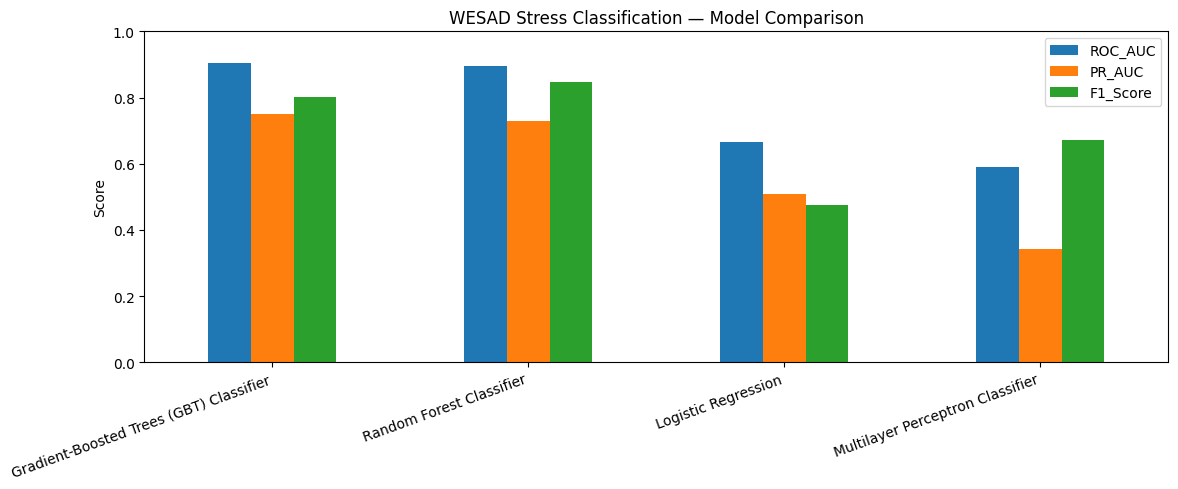

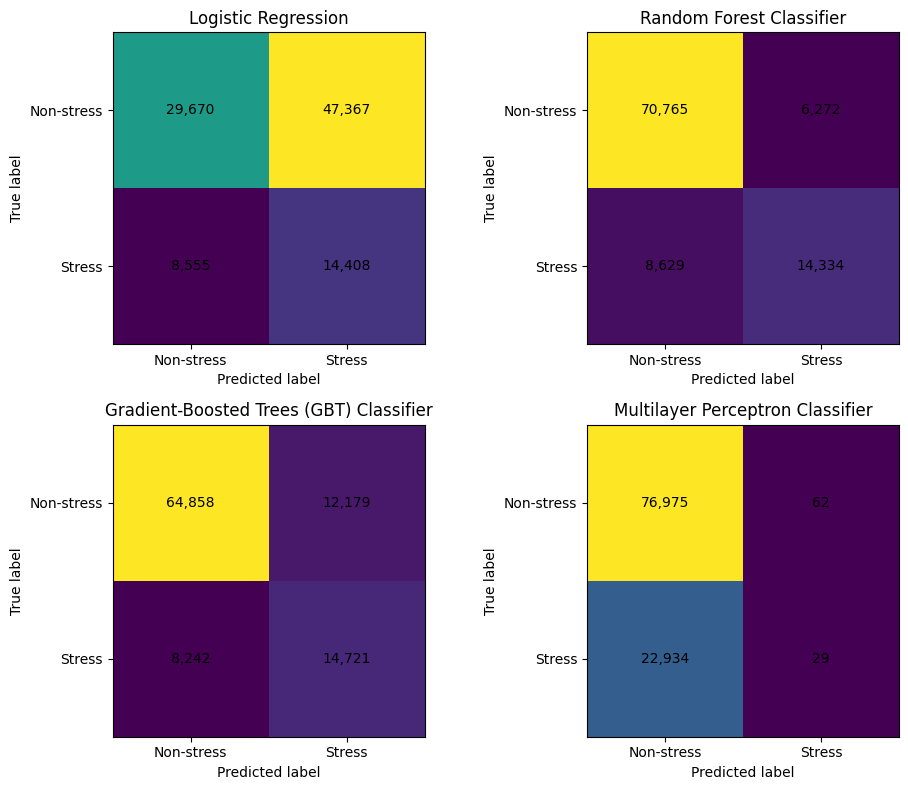

In [ ]:
ax = results_df.set_index("Model")[["ROC_AUC", "PR_AUC", "F1_Score"]].plot(
    kind="bar", figsize=(12, 5), ylim=(0, 1)
)
ax.set_title("WESAD Stress Classification — Model Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()
for ax, (name, cm) in zip(axes, confusion_matrices.items()):
    image = ax.imshow(cm, interpolation="nearest")
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks([0, 1], labels=["Non-stress", "Stress"])
    ax.set_yticks([0, 1], labels=["Non-stress", "Stress"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")
fig.tight_layout()
plt.show()

### Save the comparison table, confusion matrices, best model, and run metadata to Google Drive.


In [ ]:
RESULTS_DIR = Path("/content/drive/MyDrive/wesad_task3_outputs")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(RESULTS_DIR / "task3_model_comparison.csv", index=False)

best_name = str(results_df.iloc[0]["Model"])
best_model = fitted_models[best_name]
best_model.write().overwrite().save(str(RESULTS_DIR / "best_model"))

for name, cm in confusion_matrices.items():
    safe_name = (
        name.lower().replace(" ", "_").replace("(", "").replace(")", "")
        .replace("-", "_")
    )
    pd.DataFrame(
        cm,
        index=["Actual_Non_stress", "Actual_Stress"],
        columns=["Predicted_Non_stress", "Predicted_Stress"]
    ).to_csv(RESULTS_DIR / f"confusion_matrix_{safe_name}.csv")

metadata = {
    "source_task2_directory": str(TASK2_DIR),
    "models": [name for name, _, _ in models_and_grids],
    "metrics": ["ROC-AUC", "PR-AUC", "F1-score", "Confusion Matrix"],
    "cross_validation_folds": 2,
    "training_rows_available": int(train_total),
    "training_rows_used": int(actual_train),
    "test_rows_available": int(test_total),
    "test_rows_used": int(actual_test),
    "training_participants": train_subjects,
    "test_participants": test_subjects,
    "target_definition": "stress=1; non-stress=0",
    "logistic_regression_class_weights": {str(k): float(v) for k, v in class_weights.items()},
    "note": "Logistic Regression uses inverse-frequency class weights; all models evaluated on held-out participants.",
    "best_model_by_roc_auc": best_name,
    "status": "completed"
}
(RESULTS_DIR / "task3_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("Best model by ROC-AUC:", best_name)
print("Saved comparison and confusion matrices to:", RESULTS_DIR)
print("Saved best model to:", RESULTS_DIR / "best_model")


Best model by ROC-AUC: Gradient-Boosted Trees (GBT) Classifier
Saved comparison and confusion matrices to: /content/drive/MyDrive/wesad_task3_outputs
Saved best model to: /content/drive/MyDrive/wesad_task3_outputs/best_model


### Print the final Task 3 evidence


In [ ]:
print("Task 3 final evidence")
print("Models evaluated:", len(results_df))
print("Models:", results_df["Model"].tolist())
print("Metrics:", ["ROC-AUC", "PR-AUC", "F1-score", "Confusion Matrix"])
print("Cross-validation folds:", 2)
print("Training sample used:", f"{actual_train:,}")
print("Test sample used:", f"{actual_test:,}")
print("Best model by ROC-AUC:", best_name)
print("Output directory:", RESULTS_DIR)
for p in sorted(RESULTS_DIR.iterdir()):
    print(p.name, "(directory)" if p.is_dir() else f"{p.stat().st_size:,} bytes")

Task 3 final evidence
Models evaluated: 4
Models: ['Gradient-Boosted Trees (GBT) Classifier', 'Random Forest Classifier', 'Logistic Regression', 'Multilayer Perceptron Classifier']
Metrics: ['ROC-AUC', 'PR-AUC', 'F1-score', 'Confusion Matrix']
Cross-validation folds: 2
Training sample used: 200,000
Test sample used: 100,000
Best model by ROC-AUC: Gradient-Boosted Trees (GBT) Classifier
Output directory: /content/drive/MyDrive/wesad_task3_outputs
best_model (directory)
confusion_matrix_gradient_boosted_trees_gbt_classifier.csv 94 bytes
confusion_matrix_logistic_regression.csv 94 bytes
confusion_matrix_multilayer_perceptron_classifier.csv 89 bytes
confusion_matrix_random_forest_classifier.csv 93 bytes
task3_metadata.json 1,076 bytes
task3_model_comparison.csv 688 bytes
